# PLUSVein RL850 — Cross-Dataset Verification (EER / ROC) + Grad-CAM

Runs **inference-only** on the 11 FYODB-trained checkpoints. PLUSVein subjects are unseen,
so we use the models as **feature extractors** and measure verification (genuine vs impostor) → **EER, ROC/AUC**.
Then Grad-CAM for qualitative "does it look at veins" analysis.

Run cells top to bottom. Each cell prints what it did.


## Cell 1 · Config — edit paths here if needed

In [11]:
import os, re, json, gc, itertools, random
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
import torchvision.transforms as T
import torchvision.models as models
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ── EDIT THESE IF YOUR PATHS DIFFER ──────────────────────────────────────────
PLUSVEIN_PREPROCESSED = r'F:\Palm Vein Multimodel V2\External\HandVein PLUSVein\HandVein_RL850_Preprocessed'
MODELS_DIR            = r'F:\Palm Vein Multimodel V2\Model\Saved Models\PalmVein_V2'
OUT_DIR               = r'F:\Palm Vein Multimodel V2\Model\Outputs\PalmVein_V2\cross_dataset_eer'

NUM_CLASSES        = 150
SEED               = 42
MAX_IMPOSTOR_PAIRS = 200_000
# Leave empty to run Grad-CAM on all registered models
GRADCAM_MODELS     = []
GRADCAM_SAMPLES    = 8

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(OUT_DIR, exist_ok=True)
print('Device:', DEVICE)
if torch.cuda.is_available(): print('GPU:', torch.cuda.get_device_name(0))

# Sanity check: do the checkpoints actually exist where we think?
_found = list(Path(MODELS_DIR).glob('*_best.pth')) if Path(MODELS_DIR).exists() else []
print(f'Checkpoints found in MODELS_DIR: {len(_found)}')
for p in _found: print('   ', p.name)
assert len(_found) > 0, f'No *_best.pth found in {MODELS_DIR} — fix MODELS_DIR above.'


Device: cuda
GPU: NVIDIA GeForce RTX 5070
Checkpoints found in MODELS_DIR: 11
    ConvNeXt_Tiny_best.pth
    DenseNet121_best.pth
    EfficientNetV2_S_best.pth
    InceptionV3_best.pth
    MobileNetV3_Large_best.pth
    PVCNN_best.pth
    RegNetY_8GF_best.pth
    ResNet101_best.pth
    ResNet50_best.pth
    VGG16_best.pth
    VGG19_best.pth


## Cell 2 · PVCNN definition (must match training)

In [2]:
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(channels, channels // reduction), nn.GELU(),
            nn.Linear(channels // reduction, channels), nn.Sigmoid())
    def forward(self, x):
        w = self.se(x).unsqueeze(-1).unsqueeze(-1)
        return x * w

class MultiScaleBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        mid = out_ch // 2
        self.branch3 = nn.Sequential(nn.Conv2d(in_ch, mid, 3, padding=1, bias=False), nn.BatchNorm2d(mid), nn.GELU())
        self.branch5 = nn.Sequential(nn.Conv2d(in_ch, mid, 5, padding=2, bias=False), nn.BatchNorm2d(mid), nn.GELU())
        self.se = SEBlock(out_ch)
        self.proj = nn.Sequential(nn.Conv2d(out_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), nn.GELU())
    def forward(self, x):
        x = torch.cat([self.branch3(x), self.branch5(x)], dim=1)
        x = self.se(x)
        return self.proj(x)

class PVCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(32), nn.GELU())
        self.stage1 = nn.Sequential(MultiScaleBlock(32, 64),  nn.MaxPool2d(2))
        self.stage2 = nn.Sequential(MultiScaleBlock(64, 128), nn.MaxPool2d(2))
        self.stage3 = nn.Sequential(MultiScaleBlock(128, 256), nn.MaxPool2d(2))
        self.stage4 = nn.Sequential(MultiScaleBlock(256, 512), nn.MaxPool2d(2))
        self.pool   = nn.AdaptiveAvgPool2d(1)
        self.head   = nn.Sequential(nn.Flatten(), nn.Linear(512, 512), nn.GELU(), nn.Dropout(0.4), nn.Linear(512, num_classes))
    def forward(self, x):
        x = self.stem(x); x = self.stage1(x); x = self.stage2(x)
        x = self.stage3(x); x = self.stage4(x); x = self.pool(x)
        return self.head(x)
print('PVCNN defined.')


PVCNN defined.


## Cell 3 · Model builders + loader

In [3]:
import timm
def build_mobilenet():
    m = models.mobilenet_v3_large(); m.classifier[3] = nn.Linear(m.classifier[3].in_features, NUM_CLASSES); return m
def build_vgg16():
    m = models.vgg16(); m.classifier[6] = nn.Linear(4096, NUM_CLASSES); return m
def build_vgg19():
    m = models.vgg19(); m.classifier[6] = nn.Linear(4096, NUM_CLASSES); return m
def build_convnext():
    m = models.convnext_tiny(); m.classifier[2] = nn.Linear(m.classifier[2].in_features, NUM_CLASSES); return m
def build_inception(aux_logits=False):
    m = models.inception_v3(aux_logits=aux_logits, transform_input=False)
    if not aux_logits and getattr(m, 'AuxLogits', None) is not None:
        m.aux_logits = False; m.AuxLogits = None
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES); return m
def build_resnet50():
    m = models.resnet50(); m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES); return m
def build_resnet101():
    m = models.resnet101(); m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES); return m
def build_densenet():
    m = models.densenet121(); m.classifier = nn.Linear(m.classifier.in_features, NUM_CLASSES); return m
def build_regnet():
    m = models.regnet_y_8gf(); m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES); return m

MODEL_REGISTRY = {
    'EfficientNetV2_S':  lambda: timm.create_model('tf_efficientnetv2_s', pretrained=False, num_classes=NUM_CLASSES),
    'ResNet50': build_resnet50, 'ResNet101': build_resnet101, 'DenseNet121': build_densenet,
    'MobileNetV3_Large': build_mobilenet, 'VGG16': build_vgg16, 'VGG19': build_vgg19,
    'InceptionV3': lambda: build_inception(False), 'RegNetY_8GF': build_regnet,
    'ConvNeXt_Tiny': build_convnext, 'PVCNN': lambda: PVCNN(NUM_CLASSES),
}

def extract_state_dict(raw):
    sd = raw.get('state_dict', raw.get('model_state_dict', raw)) if isinstance(raw, dict) else raw
    return {(k[7:] if k.startswith('module.') else k): v for k, v in sd.items()}

def load_model(name):
    ckpt = os.path.join(MODELS_DIR, f'{name}_best.pth')
    if not os.path.exists(ckpt):
        print('  MISSING:', name); return None
    raw = torch.load(ckpt, map_location=DEVICE)
    sd  = extract_state_dict(raw)
    m   = MODEL_REGISTRY[name]()
    try: m.load_state_dict(sd, strict=True)
    except Exception: m.load_state_dict(sd, strict=False); print('  (non-strict)', name)
    return m.to(DEVICE).eval()
print('Builders ready.')


Builders ready.


## Cell 4 · Feature extractors (strip the head)

In [4]:
def to_feature_extractor(name, model):
    if name.startswith('ResNet') or name == 'RegNetY_8GF':
        net = nn.Sequential(*list(model.children())[:-1])
        return lambda x: torch.flatten(net(x), 1)
    if name == 'DenseNet121':
        feats = model.features
        return lambda x: torch.flatten(nn.functional.adaptive_avg_pool2d(nn.functional.relu(feats(x)), 1), 1)
    if name in ('VGG16', 'VGG19'):
        feats, avg = model.features, model.avgpool
        clf = nn.Sequential(*list(model.classifier.children())[:-1])
        return lambda x: clf(torch.flatten(avg(feats(x)), 1))
    if name == 'ConvNeXt_Tiny':
        feats, avg = model.features, model.avgpool
        return lambda x: torch.flatten(avg(feats(x)), 1)
    if name == 'MobileNetV3_Large':
        feats, avg = model.features, model.avgpool
        return lambda x: torch.flatten(avg(feats(x)), 1)
    if name == 'InceptionV3':
        def fwd(x):
            m = model
            x = m.Conv2d_1a_3x3(x); x = m.Conv2d_2a_3x3(x); x = m.Conv2d_2b_3x3(x); x = m.maxpool1(x)
            x = m.Conv2d_3b_1x1(x); x = m.Conv2d_4a_3x3(x); x = m.maxpool2(x)
            x = m.Mixed_5b(x); x = m.Mixed_5c(x); x = m.Mixed_5d(x)
            x = m.Mixed_6a(x); x = m.Mixed_6b(x); x = m.Mixed_6c(x); x = m.Mixed_6d(x); x = m.Mixed_6e(x)
            x = m.Mixed_7a(x); x = m.Mixed_7b(x); x = m.Mixed_7c(x)
            return torch.flatten(nn.functional.adaptive_avg_pool2d(x, 1), 1)
        return fwd
    if name == 'EfficientNetV2_S':
        return lambda x: model.forward_features(x).mean(dim=(2, 3))
    if name == 'PVCNN':
        def fwd(x):
            x = model.stem(x); x = model.stage1(x); x = model.stage2(x)
            x = model.stage3(x); x = model.stage4(x); x = model.pool(x)
            return torch.flatten(x, 1)
        return fwd
    raise ValueError(name)

def transform_for(name):
    size = 299 if name == 'InceptionV3' else 224
    return T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
print('Feature extractors ready.')


Feature extractors ready.


## Cell 5 · Build identity list + genuine/impostor pairs
Identity = subject + hand (per-hand, the locked decision).

In [5]:
def parse_identity(fname):
    stem = Path(fname).stem
    parts = stem.split('_')
    subj = parts[1] if len(parts) > 1 else parts[0]
    hm = re.search(r'_([LR])[-_]', stem) or re.search(r'([LR])-PALMAR', stem)
    hand = hm.group(1) if hm else ('L' if '_L' in stem else 'R' if '_R' in stem else '?')
    return f'{subj}_{hand}'

img_paths = sorted(Path(PLUSVEIN_PREPROCESSED).glob('*.png'))
assert img_paths, f'No images at {PLUSVEIN_PREPROCESSED}'
identities = [parse_identity(p.name) for p in img_paths]
uniq = sorted(set(identities))
labels = np.array([uniq.index(i) for i in identities])
print(f'{len(img_paths)} images | {len(uniq)} hand-identities')
print('example ids:', uniq[:6])

idx_by_id = {}
for i, lab in enumerate(labels): idx_by_id.setdefault(lab, []).append(i)
genuine_pairs = []
for idxs in idx_by_id.values(): genuine_pairs += list(itertools.combinations(idxs, 2))
all_pairs = list(itertools.combinations(range(len(img_paths)), 2))
gset = set(genuine_pairs)
impostor_pairs = [p for p in all_pairs if p not in gset]
if len(impostor_pairs) > MAX_IMPOSTOR_PAIRS:
    impostor_pairs = random.sample(impostor_pairs, MAX_IMPOSTOR_PAIRS)
print(f'Genuine pairs: {len(genuine_pairs)} | Impostor pairs: {len(impostor_pairs)}')


420 images | 84 hand-identities
example ids: ['001_L', '001_R', '002_L', '002_R', '003_L', '003_R']
Genuine pairs: 840 | Impostor pairs: 87150


## Cell 6 · Metric helpers

In [6]:
def compute_eer(genuine, impostor):
    y = np.concatenate([np.ones_like(genuine), np.zeros_like(impostor)])
    s = np.concatenate([genuine, impostor])
    fpr, tpr, thr = roc_curve(y, s)
    fnr = 1 - tpr
    idx = np.nanargmin(np.abs(fnr - fpr))
    return (fpr[idx]+fnr[idx])/2*100, auc(fpr, tpr), fpr, tpr, thr[idx]

def cosine_matrix(emb):
    emb = emb / (np.linalg.norm(emb, axis=1, keepdims=True) + 1e-10)
    return emb @ emb.T
print('ok')


ok


## Cell 7 · Run verification across all 11 models
This is the main compute. Watch the per-model progress bars.

  EfficientNetV2_S     | EER   5.72% | AUC 0.9878


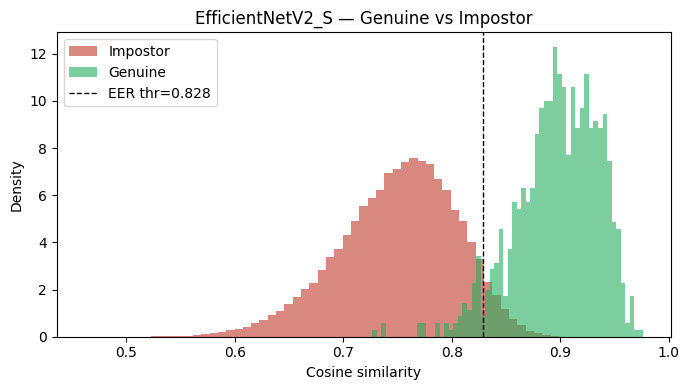

  ResNet50             | EER  15.13% | AUC 0.9279


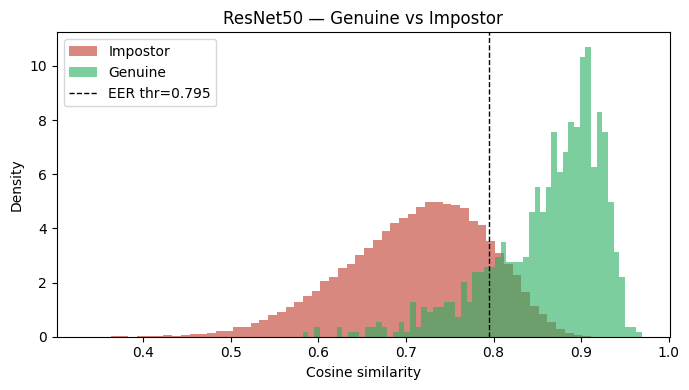

  ResNet101            | EER  13.66% | AUC 0.9332


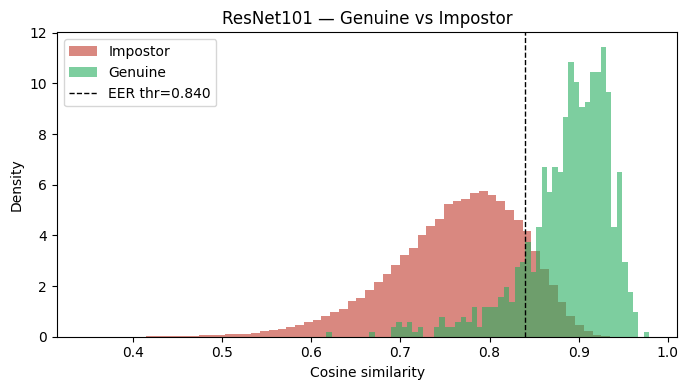

  DenseNet121          | EER   6.06% | AUC 0.9822


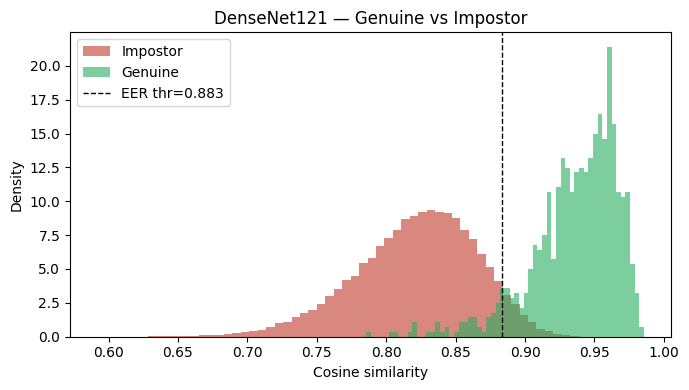

  MobileNetV3_Large    | EER   5.47% | AUC 0.9859


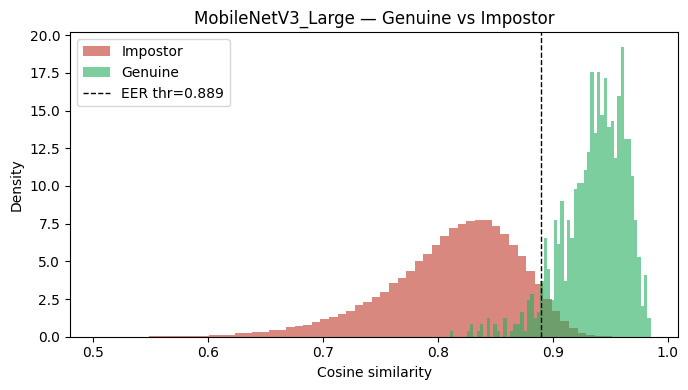

  VGG16                | EER   5.93% | AUC 0.9849


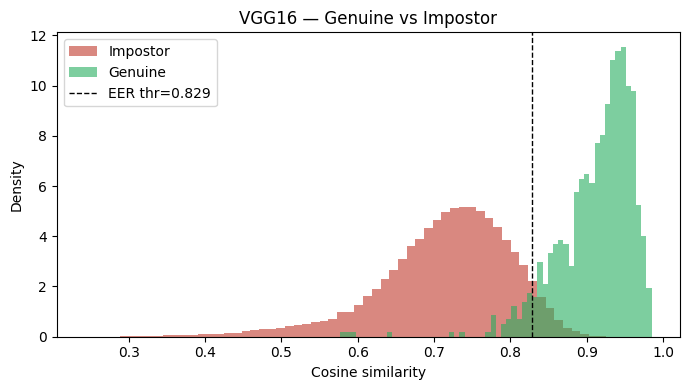

  VGG19                | EER   6.54% | AUC 0.9823


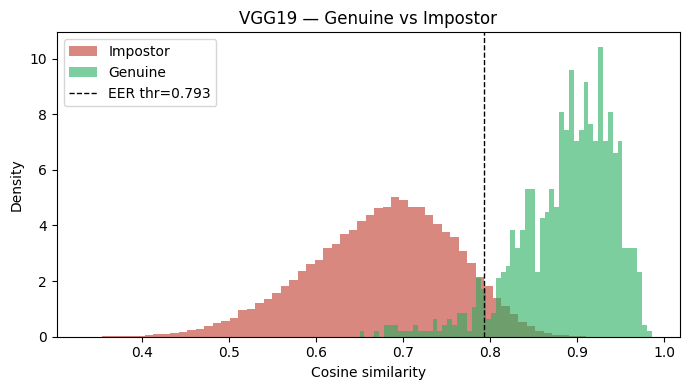

c:\Users\SMHC\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


  InceptionV3          | EER  21.26% | AUC 0.8672


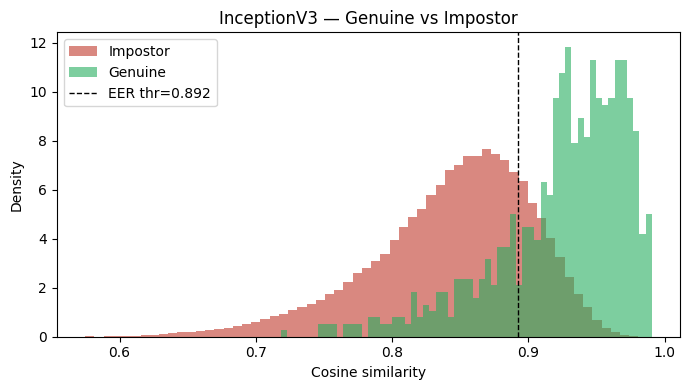

  RegNetY_8GF          | EER   8.69% | AUC 0.9753


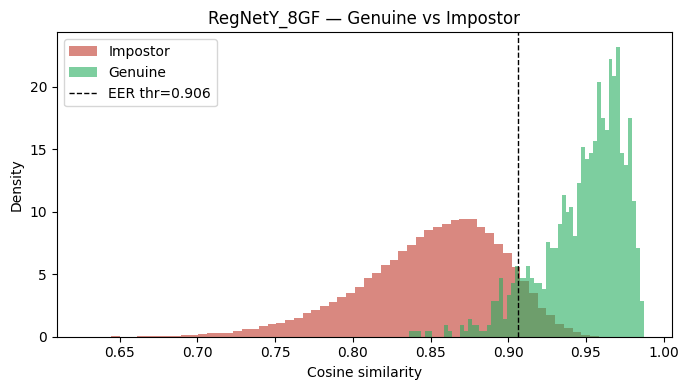

  ConvNeXt_Tiny        | EER   4.02% | AUC 0.9926


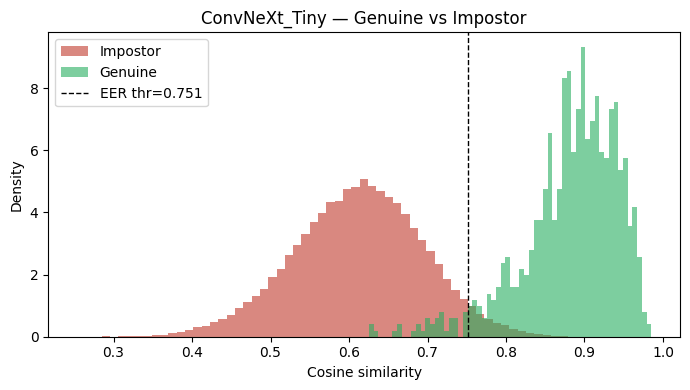

  PVCNN                | EER  28.22% | AUC 0.7906


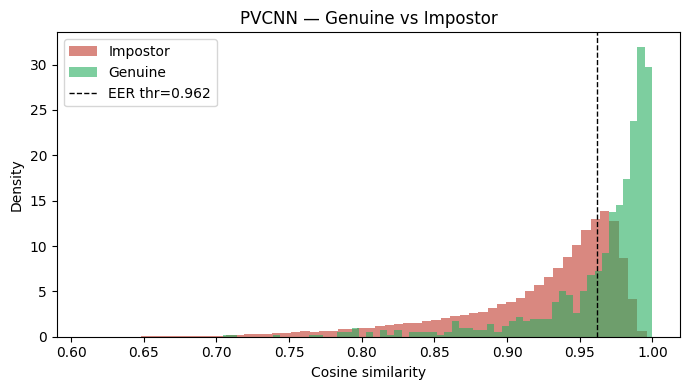

In [7]:
summary, roc_curves = [], {}
for name in MODEL_REGISTRY:
    model = load_model(name)
    if model is None: continue
    feat_fn = to_feature_extractor(name, model)
    tfm = transform_for(name)
    embs = []
    with torch.no_grad():
        for p in tqdm(img_paths, desc=f'{name}', leave=False):
            x = tfm(Image.open(p).convert('RGB')).unsqueeze(0).to(DEVICE)
            with torch.autocast('cuda', enabled=torch.cuda.is_available()):
                e = feat_fn(x)
            embs.append(e.float().squeeze(0).cpu().numpy())
    embs = np.stack(embs)
    sim = cosine_matrix(embs)
    gen = np.array([sim[i,j] for i,j in genuine_pairs])
    imp = np.array([sim[i,j] for i,j in impostor_pairs])
    eer, rocauc, fpr, tpr, thr = compute_eer(gen, imp)
    roc_curves[name] = (fpr, tpr, eer, rocauc)
    summary.append({'Model':name,'EER_%':round(eer,3),'ROC_AUC':round(rocauc,4),
                    'Genuine_mean':round(float(gen.mean()),4),'Impostor_mean':round(float(imp.mean()),4),
                    'Threshold':round(float(thr),4)})
    print(f'  {name:20s} | EER {eer:6.2f}% | AUC {rocauc:.4f}')
    # per-model distribution plot
    plt.figure(figsize=(7,4))
    plt.hist(imp,bins=60,alpha=0.6,label='Impostor',color='#c0392b',density=True)
    plt.hist(gen,bins=60,alpha=0.6,label='Genuine',color='#27ae60',density=True)
    plt.axvline(thr,color='k',ls='--',lw=1,label=f'EER thr={thr:.3f}')
    plt.title(f'{name} — Genuine vs Impostor'); plt.xlabel('Cosine similarity'); plt.ylabel('Density')
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR,f'dist_{name}.png'),dpi=150); plt.show()
    del model, embs; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()


## Cell 8 · Summary table + combined ROC

            Model  EER_%  ROC_AUC  Genuine_mean  Impostor_mean  Threshold
    ConvNeXt_Tiny  4.023   0.9926        0.8819         0.6116     0.7514
MobileNetV3_Large  5.470   0.9859        0.9359         0.8122     0.8893
 EfficientNetV2_S  5.722   0.9878        0.8971         0.7505     0.8284
            VGG16  5.928   0.9849        0.9126         0.7144     0.8288
      DenseNet121  6.056   0.9822        0.9362         0.8215     0.8832
            VGG19  6.537   0.9823        0.8869         0.6755     0.7927
      RegNetY_8GF  8.693   0.9753        0.9485         0.8509     0.9065
        ResNet101 13.663   0.9332        0.8877         0.7625     0.8399
         ResNet50 15.130   0.9279        0.8615         0.7117     0.7946
      InceptionV3 21.262   0.8672        0.9243         0.8441     0.8921
            PVCNN 28.221   0.7906        0.9646         0.9234     0.9621


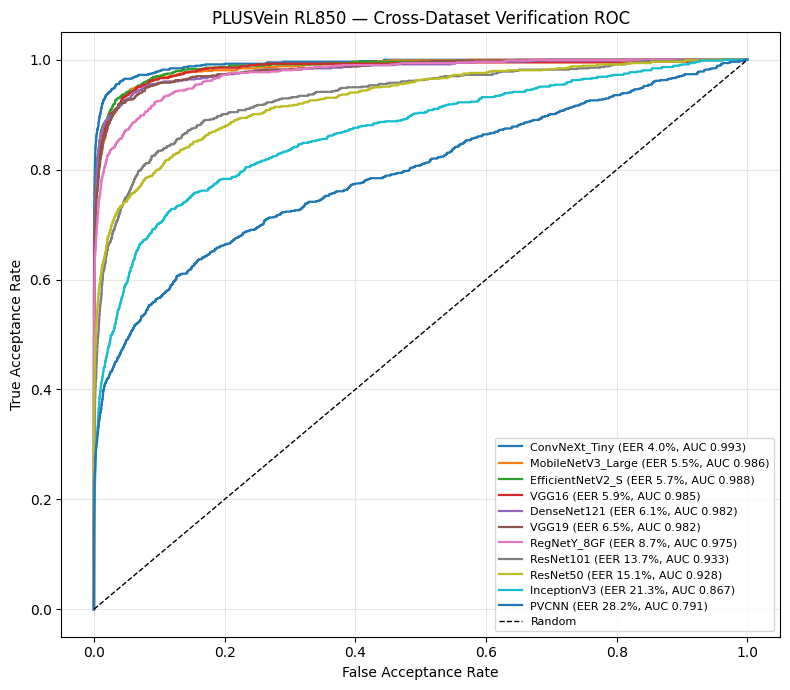

Saved to F:\Palm Vein Multimodel V2\Model\Outputs\PalmVein_V2\cross_dataset_eer


In [8]:
df = pd.DataFrame(summary).sort_values('EER_%')
df.to_csv(os.path.join(OUT_DIR,'plusvein_eer_summary.csv'), index=False)
print(df.to_string(index=False))

plt.figure(figsize=(8,7))
for name,(fpr,tpr,eer,rocauc) in sorted(roc_curves.items(), key=lambda kv: kv[1][2]):
    plt.plot(fpr,tpr,lw=1.6,label=f'{name} (EER {eer:.1f}%, AUC {rocauc:.3f})')
plt.plot([0,1],[0,1],'k--',lw=1,label='Random')
plt.xlabel('False Acceptance Rate'); plt.ylabel('True Acceptance Rate')
plt.title('PLUSVein RL850 — Cross-Dataset Verification ROC')
plt.legend(fontsize=8,loc='lower right'); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,'combined_roc.png'),dpi=150); plt.show()
print('Saved to', OUT_DIR)


## Cell 9 · Grad-CAM (qualitative — does it attend to veins?)

In [9]:
import sys
!{sys.executable} -m pip install grad-cam


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


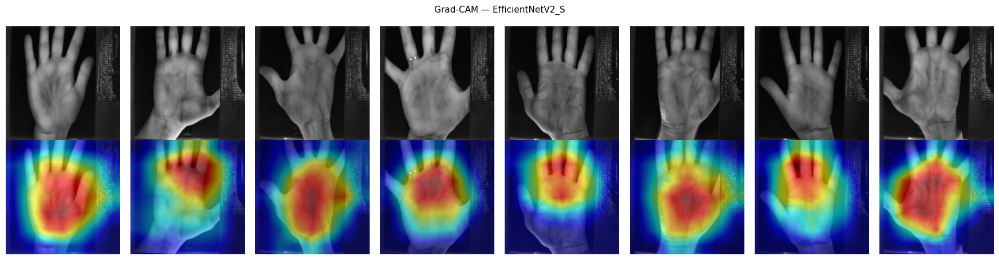

Grad-CAM saved: EfficientNetV2_S


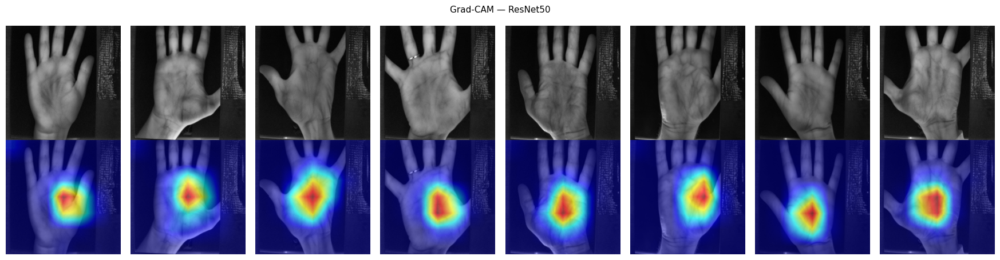

Grad-CAM saved: ResNet50


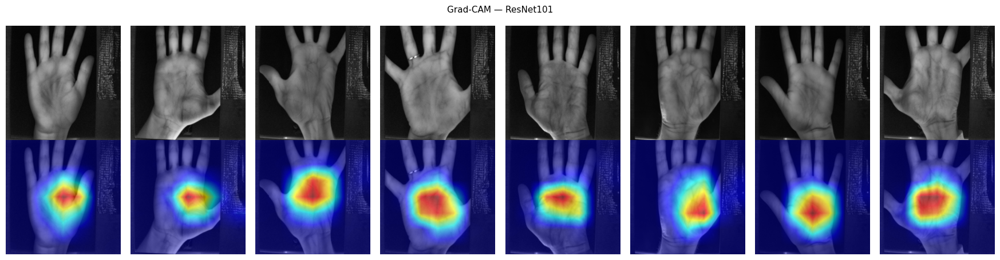

Grad-CAM saved: ResNet101


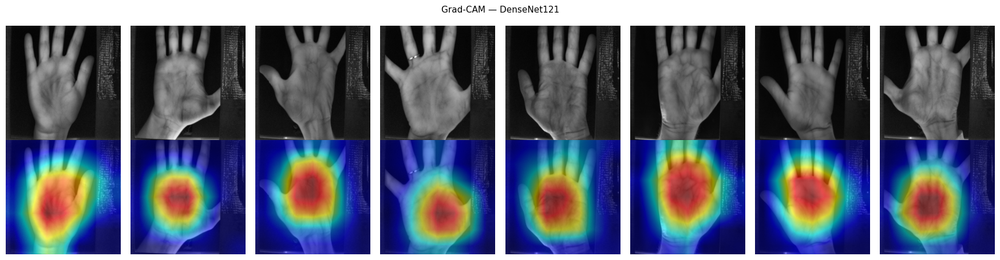

Grad-CAM saved: DenseNet121


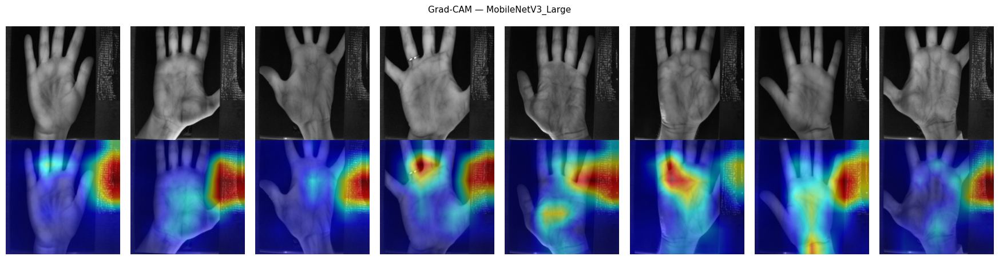

Grad-CAM saved: MobileNetV3_Large


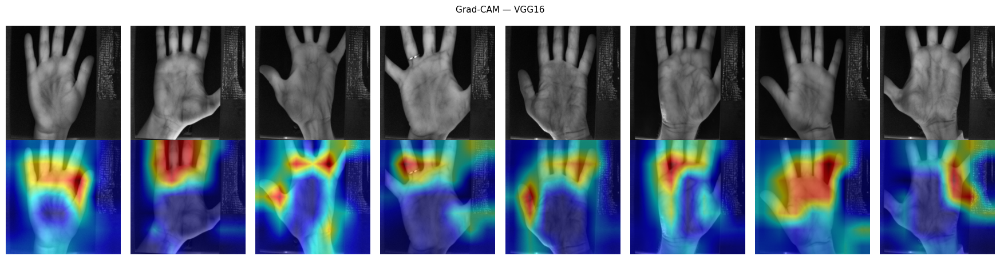

Grad-CAM saved: VGG16


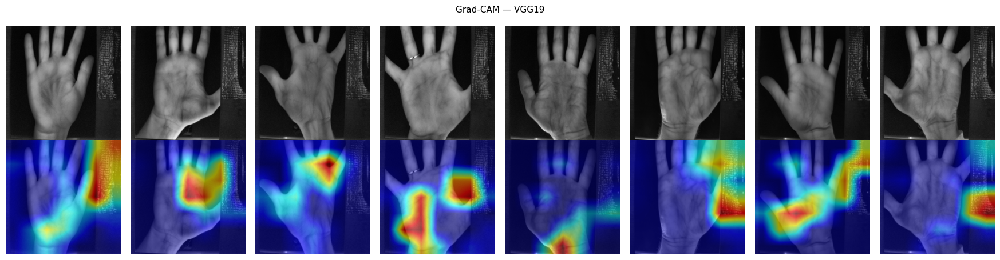

Grad-CAM saved: VGG19


c:\Users\SMHC\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\models\inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


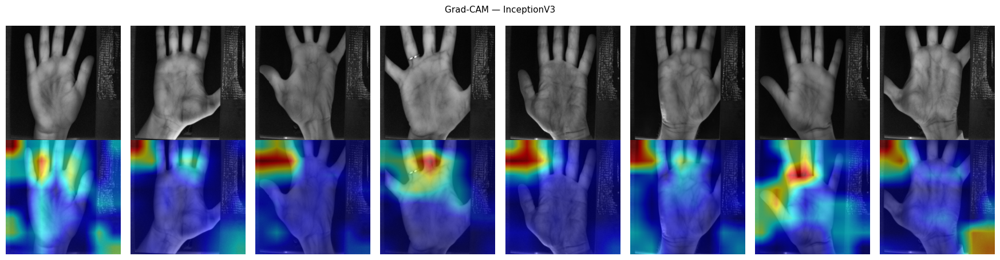

Grad-CAM saved: InceptionV3


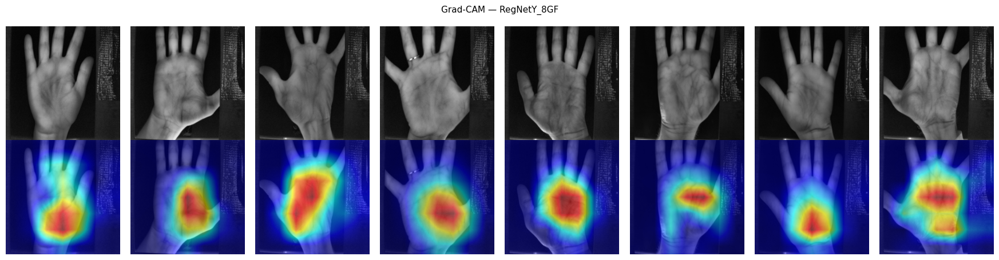

Grad-CAM saved: RegNetY_8GF


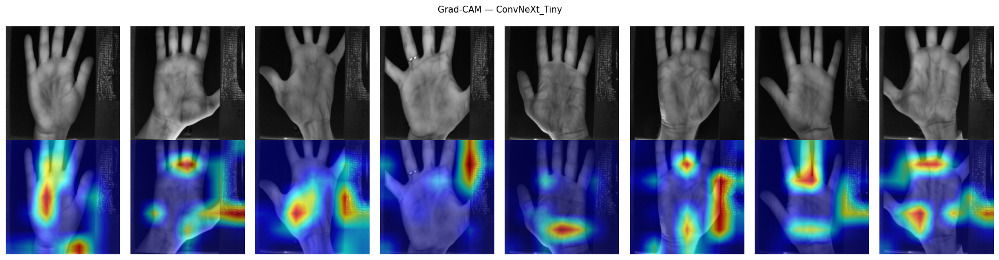

Grad-CAM saved: ConvNeXt_Tiny


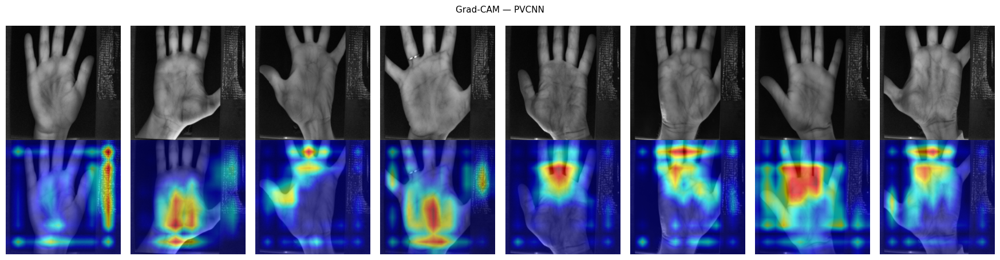

Grad-CAM saved: PVCNN
Done. Everything in F:\Palm Vein Multimodel V2\Model\Outputs\PalmVein_V2\cross_dataset_eer


In [12]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

def gradcam_target_layer(name, model):
    if name.startswith('ResNet'):   return [model.layer4[-1]]
    if name == 'RegNetY_8GF':       return [model.trunk_output[-1]]
    if name == 'DenseNet121':       return [model.features[-1]]
    if name in ('VGG16','VGG19'):   return [model.features[-1]]
    if name == 'ConvNeXt_Tiny':     return [model.features[-1][-1]]
    if name == 'MobileNetV3_Large': return [model.features[-1]]
    if name == 'PVCNN':             return [model.stage4[0].proj[0]]
    if name == 'EfficientNetV2_S':  return [model.conv_head]
    if name == 'InceptionV3':       return [model.Mixed_7c]
    return None

def find_last_conv(model):
    for m in reversed(list(model.modules())):
        if isinstance(m, nn.Conv2d):
            return m
    return None

cam_dir = os.path.join(OUT_DIR,'gradcam'); os.makedirs(cam_dir, exist_ok=True)
samples = random.sample(img_paths, min(GRADCAM_SAMPLES, len(img_paths)))
# If GRADCAM_MODELS is empty or None, run on all registered models
models_to_run = GRADCAM_MODELS if (GRADCAM_MODELS and len(GRADCAM_MODELS)>0) else list(MODEL_REGISTRY.keys())
for name in models_to_run:
    model = load_model(name)
    if model is None: continue
    layers = gradcam_target_layer(name, model)
    if layers is None:
        # fallback: pick last Conv2d in the model
        conv = find_last_conv(model)
        if conv is None:
            print('  No suitable target layer for', name, '- skipping')
            continue
        else:
            layers = [conv]
            print('  Fallback target layer used for', name, '->', type(conv))
    tfm = transform_for(name)
    cam = GradCAM(model=model, target_layers=layers)
    fig, axes = plt.subplots(2, len(samples), figsize=(2.2*len(samples), 4.6))
    for j,p in enumerate(samples):
        img = Image.open(p).convert('RGB')
        x = tfm(img).unsqueeze(0).to(DEVICE)
        g = cam(input_tensor=x)[0]
        size = 299 if name=='InceptionV3' else 224
        base = np.array(img.resize((size,size)),dtype=np.float32)/255.0
        vis = show_cam_on_image(base, g, use_rgb=True)
        axes[0][j].imshow(base); axes[0][j].axis('off')
        axes[1][j].imshow(vis);  axes[1][j].axis('off')
    fig.suptitle(f'Grad-CAM — {name}', fontsize=11); plt.tight_layout()
    plt.savefig(os.path.join(cam_dir,f'gradcam_{name}.png'),dpi=150); plt.show()
    print('Grad-CAM saved:', name)
    del model, cam; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
print('Done. Everything in', OUT_DIR)


In [1]:
import os
root = r"F:\Palm Vein Multimodel V2\Dataset FYO"   # your FYODB path
classes = [d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))]
total = sum(len(os.listdir(os.path.join(root, c))) for c in classes)
print("FYODB subjects/classes:", len(classes))
print("FYODB total images:", total)
print("images per class (first 5):", [len(os.listdir(os.path.join(root, c))) for c in classes[:5]])

FYODB subjects/classes: 150
FYODB total images: 6000
images per class (first 5): [40, 40, 40, 40, 40]
